# NYC Taxi Demand Prediction & Big Data Analytics Platform

## Project Overview

This project analyzes January 2025 NYC Yellow Taxi trip data using PySpark, Spark SQL, and machine learning. The goal is to identify when and where taxi demand is highest, examine revenue and trip patterns, and build a model for zone-level hourly demand prediction.

## Business Questions

- When does taxi demand peak throughout the day and week?
- Which NYC taxi zones generate the highest trip demand?
- How does demand differ between weekdays and weekends?
- How does pickup demand vary across days and hours?
- Which locations generate the most pickup revenue?
- Can recent trip patterns be used to predict hourly taxi demand?
- Which features contribute most to the demand model?

## Technologies

- Python
- PySpark
- Spark SQL
- Pandas
- Matplotlib
- Machine Learning
- Google Colab

## Phase 1 — Environment Setup

Set up PySpark and import the libraries used throughout the analysis.

In [2]:
!pip install -q pyspark

In [3]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.types import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

spark = (
    SparkSession.builder
    .appName("NYCTaxiDemandAnalytics")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

print("Spark version:", spark.version)
print("Project environment ready.")

Spark version: 4.0.4
Project environment ready.


## Phase 2 — Data Ingestion & Initial Quality Assessment

Load the January 2025 NYC Yellow Taxi Parquet file and inspect its size, schema, sample records, and pickup-date range.

In [7]:
# ============================================================
# PHASE 2 — DATA INGESTION & INITIAL QUALITY ASSESSMENT
# ============================================================

# January 2025 NYC Yellow Taxi Trip Records
taxi_url = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "trip-data/yellow_tripdata_2025-01.parquet"
)

file_path = "yellow_tripdata_2025-01.parquet"

# ------------------------------------------------------------
# 1. DOWNLOAD DATASET
# ------------------------------------------------------------

!wget -q "$taxi_url" -O "$file_path"

print("Dataset downloaded successfully.")


# ------------------------------------------------------------
# 2. LOAD DATA WITH PYSPARK
# ------------------------------------------------------------

taxi_df = spark.read.parquet(file_path)

row_count = taxi_df.count()
column_count = len(taxi_df.columns)

print("\n" + "=" * 70)
print("DATASET OVERVIEW")
print("=" * 70)

print(f"Number of rows: {row_count:,}")
print(f"Number of columns: {column_count}")


# ------------------------------------------------------------
# 3. INSPECT SCHEMA
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET SCHEMA")
print("=" * 70)

taxi_df.printSchema()


# ------------------------------------------------------------
# 4. PREVIEW DATA
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SAMPLE RECORDS")
print("=" * 70)

taxi_df.show(5, truncate=False)


# ------------------------------------------------------------
# 5. INITIAL DATE RANGE
# ------------------------------------------------------------

initial_date_range = taxi_df.select(
    F.min("tpep_pickup_datetime").alias("earliest_pickup"),
    F.max("tpep_pickup_datetime").alias("latest_pickup")
).first()

print("\n" + "=" * 70)
print("INITIAL DATA CHECK")
print("=" * 70)

print(
    f"Pickup range: "
    f"{initial_date_range['earliest_pickup']} "
    f"to {initial_date_range['latest_pickup']}"
)

print("\nPhase 2 complete.")

Dataset downloaded successfully.


Dataset loaded successfully.
Number of rows: 3,475,226
Number of columns: 20


root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)



+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|VendorID|tpep_pickup_datetime|tpep_dropoff_datetime|passenger_count|trip_distance|RatecodeID|store_and_fwd_flag|PULocationID|DOLocationID|payment_type|fare_amount|extra|mta_tax|tip_amount|tolls_amount|improvement_surcharge|total_amount|congestion_surcharge|Airport_fee|cbd_congestion_fee|
+--------+--------------------+---------------------+---------------+-------------+----------+------------------+------------+------------+------------+-----------+-----+-------+----------+------------+---------------------+------------+--------------------+-----------+------------------+
|1       |2025-01-01 00:18:38 |2025-01-01 00:26:59  |1              |1.6          |1         |N                 |229         |237 

## Phase 3 — Data Quality Assessment & Cleaning

Check missing values, duplicates, invalid fares, distances, timestamps, and location IDs. The cleaned dataset is restricted to January 2025 and includes additional time and revenue fields for analysis.

In [8]:
# ============================================================
# PHASE 3 — DATA QUALITY ASSESSMENT & CLEANING
# ============================================================

from pyspark.sql import functions as F

# Cache original dataset because it will be used repeatedly
taxi_df = taxi_df.cache()

original_rows = taxi_df.count()

print("=" * 70)
print("1. ORIGINAL DATASET")
print("=" * 70)

print(f"Rows: {original_rows:,}")
print(f"Columns: {len(taxi_df.columns)}")

# ------------------------------------------------------------
# DATE RANGE
# ------------------------------------------------------------

date_stats = taxi_df.select(
    F.min("tpep_pickup_datetime").alias("earliest_pickup"),
    F.max("tpep_pickup_datetime").alias("latest_pickup"),
    F.min("tpep_dropoff_datetime").alias("earliest_dropoff"),
    F.max("tpep_dropoff_datetime").alias("latest_dropoff")
).first()

print("\nPickup date range:")
print(date_stats["earliest_pickup"], "to", date_stats["latest_pickup"])

# ------------------------------------------------------------
# MISSING VALUES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("2. MISSING VALUES")
print("=" * 70)

null_counts = taxi_df.select([
    F.sum(F.col(c).isNull().cast("int")).alias(c)
    for c in taxi_df.columns
])

null_counts.show(vertical=True)

# ------------------------------------------------------------
# DUPLICATES
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("3. DUPLICATE ROWS")
print("=" * 70)

distinct_rows = taxi_df.dropDuplicates().count()
duplicate_rows = original_rows - distinct_rows

print(f"Duplicate rows: {duplicate_rows:,}")

# ------------------------------------------------------------
# INVALID / SUSPICIOUS RECORDS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("4. DATA QUALITY CHECKS")
print("=" * 70)

quality = taxi_df.select(
    F.sum((F.col("trip_distance") <= 0).cast("int"))
        .alias("non_positive_distance"),

    F.sum((F.col("fare_amount") <= 0).cast("int"))
        .alias("non_positive_fare"),

    F.sum(
        (
            F.col("tpep_dropoff_datetime")
            <= F.col("tpep_pickup_datetime")
        ).cast("int")
    ).alias("invalid_time_order"),

    F.sum(
        (
            F.col("PULocationID").isNull()
            | (F.col("PULocationID") <= 0)
        ).cast("int")
    ).alias("invalid_pickup_location"),

    F.sum(
        (
            F.col("DOLocationID").isNull()
            | (F.col("DOLocationID") <= 0)
        ).cast("int")
    ).alias("invalid_dropoff_location")
)

quality.show(vertical=True)

# ------------------------------------------------------------
# CREATE CLEAN DATASET
# ------------------------------------------------------------

clean_df = (
    taxi_df

    # Remove duplicate rows
    .dropDuplicates()

    # Valid timestamps
    .filter(
        F.col("tpep_pickup_datetime").isNotNull()
        & F.col("tpep_dropoff_datetime").isNotNull()
    )

    # Keep January 2025 pickup records
    .filter(
        (F.col("tpep_pickup_datetime") >= "2025-01-01")
        & (F.col("tpep_pickup_datetime") < "2025-02-01")
    )

    # Positive distance and fare
    .filter(F.col("trip_distance") > 0)
    .filter(F.col("fare_amount") > 0)

    # Valid location IDs
    .filter(F.col("PULocationID").isNotNull())
    .filter(F.col("DOLocationID").isNotNull())
    .filter(F.col("PULocationID") > 0)
    .filter(F.col("DOLocationID") > 0)

    # Dropoff must occur after pickup
    .filter(
        F.col("tpep_dropoff_datetime")
        > F.col("tpep_pickup_datetime")
    )
)

# ------------------------------------------------------------
# FEATURE ENGINEERING
# ------------------------------------------------------------

clean_df = (
    clean_df

    # Trip duration in minutes
    .withColumn(
        "trip_duration_minutes",
        (
            F.unix_timestamp("tpep_dropoff_datetime")
            - F.unix_timestamp("tpep_pickup_datetime")
        ) / 60
    )

    # Calendar features
    .withColumn("pickup_date", F.to_date("tpep_pickup_datetime"))
    .withColumn("pickup_hour", F.hour("tpep_pickup_datetime"))
    .withColumn("pickup_day", F.dayofmonth("tpep_pickup_datetime"))
    .withColumn("day_of_week", F.dayofweek("tpep_pickup_datetime"))
    .withColumn("day_name", F.date_format("tpep_pickup_datetime", "EEEE"))

    # Weekend flag
    .withColumn(
        "is_weekend",
        F.when(F.col("day_of_week").isin(1, 7), 1).otherwise(0)
    )

    # Revenue per trip
    .withColumn(
        "trip_revenue",
        F.when(F.col("total_amount") > 0, F.col("total_amount"))
         .otherwise(F.col("fare_amount"))
    )
)

# Remove unrealistic durations
clean_df = clean_df.filter(
    (F.col("trip_duration_minutes") >= 1)
    & (F.col("trip_duration_minutes") <= 180)
)

clean_df = clean_df.cache()

clean_rows = clean_df.count()
removed_rows = original_rows - clean_rows
retention_rate = clean_rows / original_rows * 100

print("\n" + "=" * 70)
print("5. CLEANING RESULTS")
print("=" * 70)

print(f"Original rows: {original_rows:,}")
print(f"Clean rows:    {clean_rows:,}")
print(f"Rows removed:  {removed_rows:,}")
print(f"Data retained: {retention_rate:.2f}%")

# ------------------------------------------------------------
# CLEAN DATASET SUMMARY
# ------------------------------------------------------------

summary = clean_df.select(
    F.count("*").alias("trips"),
    F.round(F.sum("trip_revenue"), 2).alias("total_revenue"),
    F.round(F.avg("trip_distance"), 2).alias("avg_distance"),
    F.round(F.avg("trip_duration_minutes"), 2).alias("avg_duration_minutes"),
    F.round(F.avg("trip_revenue"), 2).alias("avg_revenue_per_trip"),
    F.round(F.avg("passenger_count"), 2).alias("avg_passengers")
)

print("\n" + "=" * 70)
print("6. CLEAN DATASET SUMMARY")
print("=" * 70)

summary.show(vertical=True)

print("\nPhase 3 complete.")

1. ORIGINAL DATASET
Rows: 3,475,226
Columns: 20

Pickup date range:
2024-12-31 20:47:55 to 2025-02-01 00:00:44

2. MISSING VALUES
-RECORD 0-----------------------
 VendorID              | 0      
 tpep_pickup_datetime  | 0      
 tpep_dropoff_datetime | 0      
 passenger_count       | 540149 
 trip_distance         | 0      
 RatecodeID            | 540149 
 store_and_fwd_flag    | 540149 
 PULocationID          | 0      
 DOLocationID          | 0      
 payment_type          | 0      
 fare_amount           | 0      
 extra                 | 0      
 mta_tax               | 0      
 tip_amount            | 0      
 tolls_amount          | 0      
 improvement_surcharge | 0      
 total_amount          | 0      
 congestion_surcharge  | 540149 
 Airport_fee           | 540149 
 cbd_congestion_fee    | 0      


3. DUPLICATE ROWS
Duplicate rows: 0

4. DATA QUALITY CHECKS
-RECORD 0--------------------------
 non_positive_distance    | 90893  
 non_positive_fare        | 145516 
 invali

## Phase 4 — Spark SQL Business Analytics

Use Spark SQL to summarize trip volume, revenue, hourly and daily demand, weekday/weekend behavior, pickup locations, payment types, and trip-distance patterns.

In [9]:
# ============================================================
# PHASE 4 — SPARK SQL BUSINESS ANALYTICS
# ============================================================

from pyspark.sql import functions as F

# Register clean dataset as a Spark SQL temporary view
clean_df.createOrReplaceTempView("taxi_trips")

print("=" * 75)
print("NYC TAXI — SPARK SQL BUSINESS ANALYTICS")
print("=" * 75)


# ------------------------------------------------------------
# 1. EXECUTIVE KPIs
# ------------------------------------------------------------

executive_kpis = spark.sql("""
SELECT
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue,
    ROUND(AVG(trip_revenue), 2) AS avg_revenue_per_trip,
    ROUND(AVG(trip_distance), 2) AS avg_trip_distance,
    ROUND(AVG(trip_duration_minutes), 2) AS avg_trip_duration,
    ROUND(AVG(passenger_count), 2) AS avg_passengers
FROM taxi_trips
""")

print("\n1. EXECUTIVE KPIs")
executive_kpis.show(truncate=False)


# ------------------------------------------------------------
# 2. HOURLY DEMAND
# ------------------------------------------------------------

hourly_demand = spark.sql("""
SELECT
    pickup_hour,
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue,
    ROUND(AVG(trip_revenue), 2) AS avg_revenue_per_trip
FROM taxi_trips
GROUP BY pickup_hour
ORDER BY pickup_hour
""")

print("\n2. HOURLY DEMAND")
hourly_demand.show(24, truncate=False)


# ------------------------------------------------------------
# 3. DAY-OF-WEEK DEMAND
# ------------------------------------------------------------

daily_demand = spark.sql("""
SELECT
    day_of_week,
    day_name,
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue,
    ROUND(AVG(trip_revenue), 2) AS avg_revenue_per_trip
FROM taxi_trips
GROUP BY day_of_week, day_name
ORDER BY day_of_week
""")

print("\n3. DEMAND BY DAY OF WEEK")
daily_demand.show(7, truncate=False)


# ------------------------------------------------------------
# 4. WEEKDAY VS WEEKEND
# ------------------------------------------------------------

weekend_analysis = spark.sql("""
SELECT
    CASE
        WHEN is_weekend = 1 THEN 'Weekend'
        ELSE 'Weekday'
    END AS period_type,

    COUNT(*) AS total_trips,

    ROUND(
        COUNT(*) * 100.0 /
        SUM(COUNT(*)) OVER (),
        2
    ) AS trip_share_pct,

    ROUND(SUM(trip_revenue), 2) AS total_revenue,

    ROUND(AVG(trip_revenue), 2) AS avg_revenue_per_trip,

    ROUND(AVG(trip_distance), 2) AS avg_trip_distance,

    ROUND(AVG(trip_duration_minutes), 2) AS avg_duration_minutes

FROM taxi_trips

GROUP BY is_weekend
ORDER BY total_trips DESC
""")

print("\n4. WEEKDAY VS WEEKEND")
weekend_analysis.show(truncate=False)


# ------------------------------------------------------------
# 5. TOP PICKUP LOCATIONS
# ------------------------------------------------------------

top_pickup_zones = spark.sql("""
SELECT
    PULocationID AS pickup_location_id,
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue,
    ROUND(AVG(trip_revenue), 2) AS avg_revenue_per_trip
FROM taxi_trips
GROUP BY PULocationID
ORDER BY total_trips DESC
LIMIT 15
""")

print("\n5. TOP 15 PICKUP LOCATION IDs")
top_pickup_zones.show(15, truncate=False)


# ------------------------------------------------------------
# 6. TOP DROPOFF LOCATIONS
# ------------------------------------------------------------

top_dropoff_zones = spark.sql("""
SELECT
    DOLocationID AS dropoff_location_id,
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue
FROM taxi_trips
GROUP BY DOLocationID
ORDER BY total_trips DESC
LIMIT 15
""")

print("\n6. TOP 15 DROPOFF LOCATION IDs")
top_dropoff_zones.show(15, truncate=False)


# ------------------------------------------------------------
# 7. BUSIEST PICKUP HOURS
# ------------------------------------------------------------

busiest_hours = spark.sql("""
SELECT
    pickup_hour,
    COUNT(*) AS total_trips,
    ROUND(
        COUNT(*) * 100.0 /
        SUM(COUNT(*)) OVER (),
        2
    ) AS trip_share_pct
FROM taxi_trips
GROUP BY pickup_hour
ORDER BY total_trips DESC
LIMIT 10
""")

print("\n7. BUSIEST HOURS")
busiest_hours.show(10, truncate=False)


# ------------------------------------------------------------
# 8. PAYMENT TYPE ANALYSIS
# ------------------------------------------------------------

payment_analysis = spark.sql("""
SELECT
    payment_type,
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue,
    ROUND(AVG(trip_revenue), 2) AS avg_revenue_per_trip,
    ROUND(AVG(tip_amount), 2) AS avg_tip
FROM taxi_trips
GROUP BY payment_type
ORDER BY total_trips DESC
""")

print("\n8. PAYMENT TYPE ANALYSIS")
payment_analysis.show(truncate=False)


# ------------------------------------------------------------
# 9. TRIP DISTANCE BANDS
# ------------------------------------------------------------

distance_analysis = spark.sql("""
SELECT
    CASE
        WHEN trip_distance < 2 THEN '< 2 miles'
        WHEN trip_distance < 5 THEN '2–5 miles'
        WHEN trip_distance < 10 THEN '5–10 miles'
        ELSE '10+ miles'
    END AS distance_band,

    COUNT(*) AS total_trips,
    ROUND(AVG(trip_revenue), 2) AS avg_revenue,
    ROUND(AVG(trip_duration_minutes), 2) AS avg_duration_minutes

FROM taxi_trips

GROUP BY
    CASE
        WHEN trip_distance < 2 THEN '< 2 miles'
        WHEN trip_distance < 5 THEN '2–5 miles'
        WHEN trip_distance < 10 THEN '5–10 miles'
        ELSE '10+ miles'
    END

ORDER BY total_trips DESC
""")

print("\n9. TRIP DISTANCE ANALYSIS")
distance_analysis.show(truncate=False)


# ------------------------------------------------------------
# 10. DAILY DEMAND
# ------------------------------------------------------------

daily_trip_volume = spark.sql("""
SELECT
    pickup_date,
    COUNT(*) AS total_trips,
    ROUND(SUM(trip_revenue), 2) AS total_revenue
FROM taxi_trips
GROUP BY pickup_date
ORDER BY pickup_date
""")

print("\n10. DAILY DEMAND — SAMPLE")
daily_trip_volume.show(10, truncate=False)


# ------------------------------------------------------------
# KEY FINDINGS
# ------------------------------------------------------------

peak_hour = (
    hourly_demand
    .orderBy(F.desc("total_trips"))
    .first()
)

peak_day = (
    daily_demand
    .orderBy(F.desc("total_trips"))
    .first()
)

peak_zone = (
    top_pickup_zones
    .orderBy(F.desc("total_trips"))
    .first()
)

print("\n" + "=" * 75)
print("KEY FINDINGS")
print("=" * 75)

print(
    f"Peak demand hour: {peak_hour['pickup_hour']}:00 "
    f"with {peak_hour['total_trips']:,} trips"
)

print(
    f"Highest-demand weekday: {peak_day['day_name']} "
    f"with {peak_day['total_trips']:,} trips"
)

print(
    f"Highest-demand pickup Location ID: "
    f"{peak_zone['pickup_location_id']} "
    f"with {peak_zone['total_trips']:,} trips"
)

print("\nPhase 4 complete.")

NYC TAXI — SPARK SQL BUSINESS ANALYTICS

1. EXECUTIVE KPIs
+-----------+-------------+--------------------+-----------------+-----------------+--------------+
|total_trips|total_revenue|avg_revenue_per_trip|avg_trip_distance|avg_trip_duration|avg_passengers|
+-----------+-------------+--------------------+-----------------+-----------------+--------------+
|3241808    |8.767982374E7|27.05               |5.53             |14.72            |1.3           |
+-----------+-------------+--------------------+-----------------+-----------------+--------------+


2. HOURLY DEMAND
+-----------+-----------+-------------+--------------------+
|pickup_hour|total_trips|total_revenue|avg_revenue_per_trip|
+-----------+-----------+-------------+--------------------+
|0          |86206      |2350900.85   |27.27               |
|1          |59279      |1490421.28   |25.14               |
|2          |40019      |962336.21    |24.05               |
|3          |25369      |633720.07    |24.98            

## Phase 5 — Demand Pattern Analysis & Visualization

Visualize the aggregated Spark results to make the main time and location patterns easier to interpret.

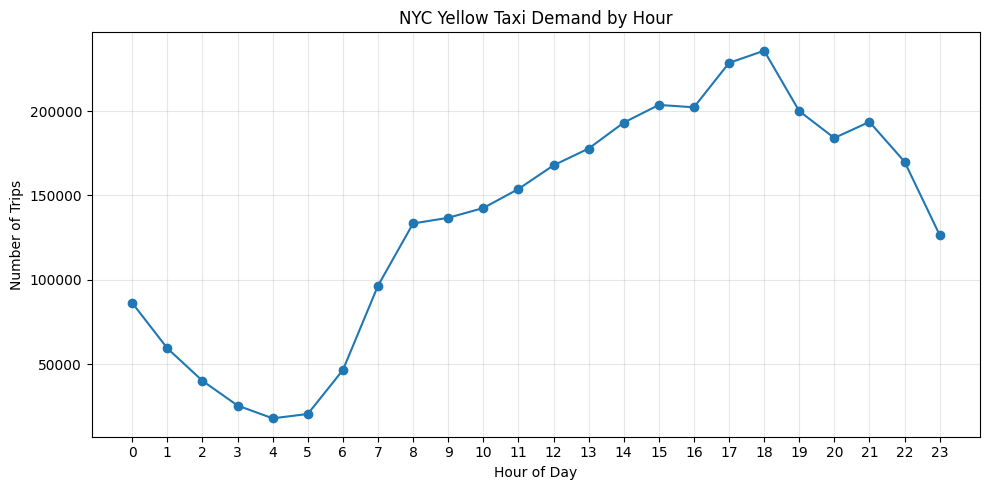

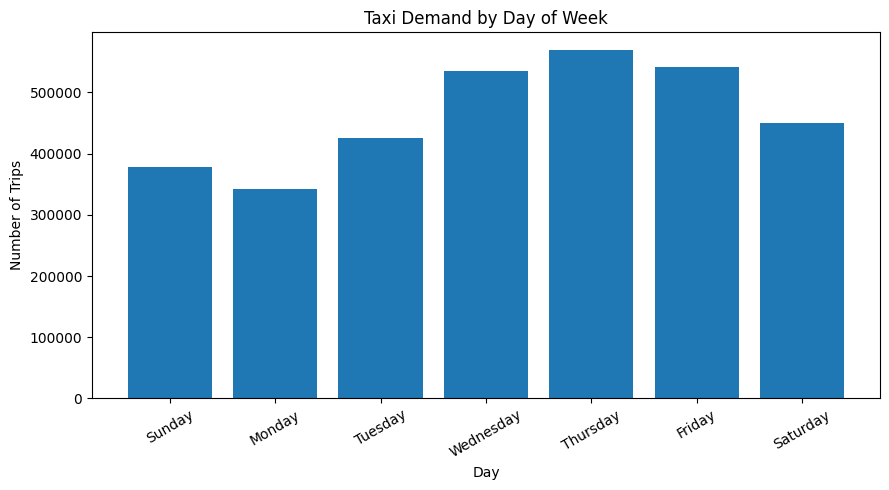

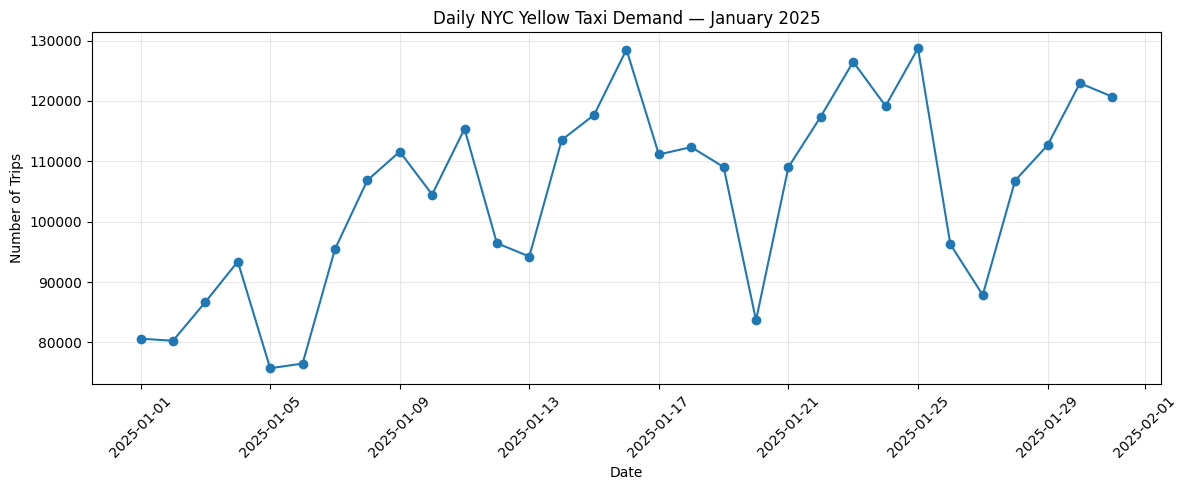

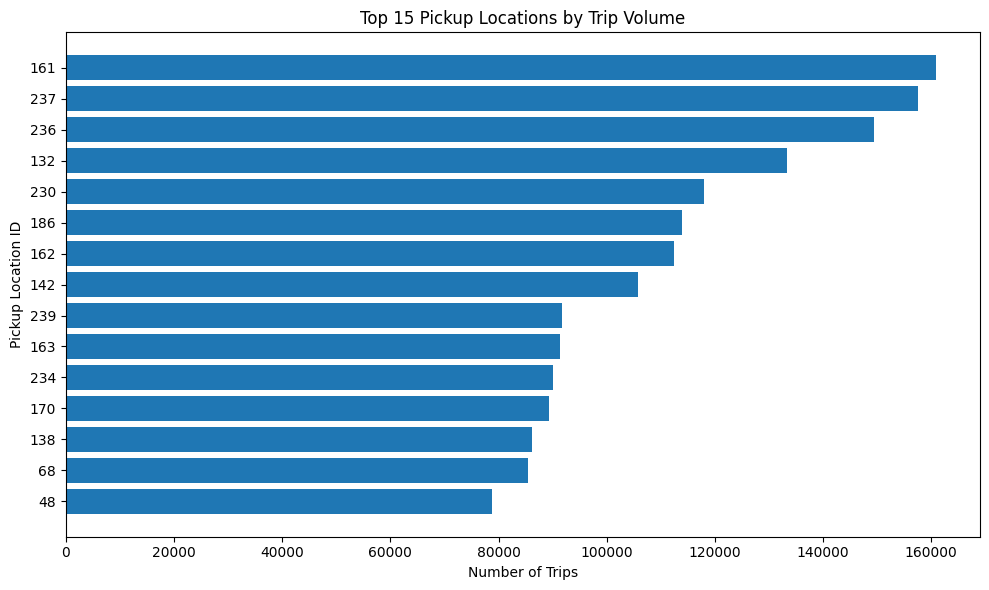

DEMAND ANALYTICS SUMMARY
Peak hour: 18:00 (235,843 trips)
Highest-demand weekday: Thursday (569,851 trips)
Highest-demand date: 2025-01-25 (128,724 trips)

Phase 5 complete.


In [10]:
# ============================================================
# PHASE 5 — DEMAND ANALYSIS & VISUALIZATION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Convert only small aggregated Spark results to Pandas
hourly_pd = hourly_demand.orderBy("pickup_hour").toPandas()

daily_pd = (
    daily_demand
    .orderBy("day_of_week")
    .toPandas()
)

daily_volume_pd = (
    daily_trip_volume
    .orderBy("pickup_date")
    .toPandas()
)

top_zones_pd = (
    top_pickup_zones
    .orderBy(F.desc("total_trips"))
    .toPandas()
)


# ------------------------------------------------------------
# 1. HOURLY TAXI DEMAND
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    hourly_pd["pickup_hour"],
    hourly_pd["total_trips"],
    marker="o"
)

plt.title("NYC Yellow Taxi Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Trips")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. DEMAND BY DAY OF WEEK
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    daily_pd["day_name"],
    daily_pd["total_trips"]
)

plt.title("Taxi Demand by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Trips")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. DAILY TRIP VOLUME
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

plt.plot(
    pd.to_datetime(daily_volume_pd["pickup_date"]),
    daily_volume_pd["total_trips"],
    marker="o"
)

plt.title("Daily NYC Yellow Taxi Demand — January 2025")
plt.xlabel("Date")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. TOP PICKUP LOCATIONS
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

plot_zones = top_zones_pd.sort_values("total_trips")

plt.barh(
    plot_zones["pickup_location_id"].astype(str),
    plot_zones["total_trips"]
)

plt.title("Top 15 Pickup Locations by Trip Volume")
plt.xlabel("Number of Trips")
plt.ylabel("Pickup Location ID")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# VISUAL ANALYTICS SUMMARY
# ------------------------------------------------------------

peak_hour_row = hourly_pd.loc[
    hourly_pd["total_trips"].idxmax()
]

peak_day_row = daily_pd.loc[
    daily_pd["total_trips"].idxmax()
]

highest_daily_row = daily_volume_pd.loc[
    daily_volume_pd["total_trips"].idxmax()
]

print("=" * 70)
print("DEMAND ANALYTICS SUMMARY")
print("=" * 70)

print(
    f"Peak hour: {int(peak_hour_row['pickup_hour'])}:00 "
    f"({int(peak_hour_row['total_trips']):,} trips)"
)

print(
    f"Highest-demand weekday: "
    f"{peak_day_row['day_name']} "
    f"({int(peak_day_row['total_trips']):,} trips)"
)

print(
    f"Highest-demand date: "
    f"{highest_daily_row['pickup_date']} "
    f"({int(highest_daily_row['total_trips']):,} trips)"
)

print("\nPhase 5 complete.")

## Phase 6 — Demand Modeling Dataset & Feature Engineering

Aggregate trips by pickup date, hour, and taxi zone to create the modeling dataset. Add calendar features and previous observed demand values for each zone.

**Note:** The lag variables refer to previous observed records within each pickup zone. Because zero-demand zone-hour combinations are not explicitly added, they should not be interpreted as guaranteed consecutive clock hours.

In [11]:
# ============================================================
# PHASE 6 — HOURLY ZONE DEMAND DATASET
# ============================================================

from pyspark.sql import functions as F
from pyspark.sql.window import Window

print("=" * 70)
print("BUILDING HOURLY ZONE DEMAND DATASET")
print("=" * 70)

# ------------------------------------------------------------
# 1. AGGREGATE TRIPS TO ZONE × DATE × HOUR
# ------------------------------------------------------------

demand_df = (
    clean_df
    .groupBy(
        "pickup_date",
        "pickup_hour",
        "PULocationID"
    )
    .agg(
        F.count("*").alias("trip_demand"),
        F.round(F.sum("trip_revenue"), 2).alias("hourly_revenue"),
        F.round(F.avg("trip_distance"), 2).alias("avg_trip_distance"),
        F.round(F.avg("trip_duration_minutes"), 2)
         .alias("avg_trip_duration")
    )
)


# ------------------------------------------------------------
# 2. TEMPORAL FEATURES
# ------------------------------------------------------------

demand_df = (
    demand_df
    .withColumn(
        "day_of_week",
        F.dayofweek("pickup_date")
    )
    .withColumn(
        "day_of_month",
        F.dayofmonth("pickup_date")
    )
    .withColumn(
        "is_weekend",
        F.when(
            F.col("day_of_week").isin(1, 7), 1
        ).otherwise(0)
    )
)


# ------------------------------------------------------------
# 3. RUSH-HOUR FEATURE
# ------------------------------------------------------------

demand_df = demand_df.withColumn(
    "is_rush_hour",
    F.when(
        F.col("pickup_hour").isin(
            7, 8, 9,
            16, 17, 18, 19
        ),
        1
    ).otherwise(0)
)


# ------------------------------------------------------------
# 4. CREATE CONTINUOUS HOURLY TIMESTAMP
# ------------------------------------------------------------

demand_df = demand_df.withColumn(
    "pickup_hour_ts",
    F.to_timestamp(
        F.concat_ws(
            " ",
            F.col("pickup_date").cast("string"),
            F.format_string(
                "%02d:00:00",
                F.col("pickup_hour")
            )
        )
    )
)


# ------------------------------------------------------------
# 5. HISTORICAL DEMAND FEATURES
# ------------------------------------------------------------

zone_window = (
    Window
    .partitionBy("PULocationID")
    .orderBy("pickup_hour_ts")
)

demand_df = (
    demand_df

    # Previous observed demand
    .withColumn(
        "lag_1_demand",
        F.lag("trip_demand", 1).over(zone_window)
    )

    .withColumn(
        "lag_2_demand",
        F.lag("trip_demand", 2).over(zone_window)
    )

    .withColumn(
        "lag_3_demand",
        F.lag("trip_demand", 3).over(zone_window)
    )
)


# ------------------------------------------------------------
# 6. REMOVE ROWS WITHOUT LAG HISTORY
# ------------------------------------------------------------

model_df = (
    demand_df
    .dropna(
        subset=[
            "lag_1_demand",
            "lag_2_demand",
            "lag_3_demand"
        ]
    )
    .cache()
)

model_rows = model_df.count()


# ------------------------------------------------------------
# 7. MODELING DATASET SUMMARY
# ------------------------------------------------------------

print(f"\nModeling observations: {model_rows:,}")

model_df.select(
    F.round(F.avg("trip_demand"), 2).alias("avg_hourly_demand"),
    F.min("trip_demand").alias("minimum_demand"),
    F.max("trip_demand").alias("maximum_demand"),
    F.round(F.stddev("trip_demand"), 2)
     .alias("demand_std_dev")
).show(truncate=False)


# ------------------------------------------------------------
# 8. PREVIEW MODEL FEATURES
# ------------------------------------------------------------

model_df.select(
    "pickup_date",
    "pickup_hour",
    "PULocationID",
    "day_of_week",
    "is_weekend",
    "is_rush_hour",
    "lag_1_demand",
    "lag_2_demand",
    "lag_3_demand",
    "trip_demand"
).orderBy(
    "pickup_date",
    "pickup_hour"
).show(10, truncate=False)

print("\nPhase 6 complete.")

BUILDING HOURLY ZONE DEMAND DATASET

Modeling observations: 90,797
+-----------------+--------------+--------------+--------------+
|avg_hourly_demand|minimum_demand|maximum_demand|demand_std_dev|
+-----------------+--------------+--------------+--------------+
|35.47            |1             |885           |72.13         |
+-----------------+--------------+--------------+--------------+

+-----------+-----------+------------+-----------+----------+------------+------------+------------+------------+-----------+
|pickup_date|pickup_hour|PULocationID|day_of_week|is_weekend|is_rush_hour|lag_1_demand|lag_2_demand|lag_3_demand|trip_demand|
+-----------+-----------+------------+-----------+----------+------------+------------+------------+------------+-----------+
|2025-01-01 |3          |161         |4          |0         |0           |140         |238         |258         |60         |
|2025-01-01 |3          |89          |4          |0         |0           |3           |5           |1  

## Phase 7 — Machine Learning Demand Prediction

Train Linear Regression and Random Forest models to predict zone-level hourly trip demand. A time-based split is used: earlier January observations form the training set and the final week is held out for testing. Performance is compared using RMSE, MAE, and R².

In [12]:
# ============================================================
# PHASE 7 — MACHINE LEARNING DEMAND PREDICTION
# ============================================================

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator

print("=" * 75)
print("TAXI DEMAND PREDICTION — MACHINE LEARNING")
print("=" * 75)

# ------------------------------------------------------------
# 1. SELECT MODEL FEATURES
# ------------------------------------------------------------

feature_columns = [
    "pickup_hour",
    "PULocationID",
    "day_of_week",
    "day_of_month",
    "is_weekend",
    "is_rush_hour",
    "lag_1_demand",
    "lag_2_demand",
    "lag_3_demand"
]

assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

ml_df = assembler.transform(model_df).select(
    "pickup_date",
    "pickup_hour",
    "PULocationID",
    "trip_demand",
    "features"
)


# ------------------------------------------------------------
# 2. TIME-BASED TRAIN / TEST SPLIT
# ------------------------------------------------------------

train_df = (
    ml_df
    .filter(F.col("pickup_date") < "2025-01-25")
    .cache()
)

test_df = (
    ml_df
    .filter(F.col("pickup_date") >= "2025-01-25")
    .cache()
)

train_count = train_df.count()
test_count = test_df.count()

print(f"\nTraining observations: {train_count:,}")
print(f"Testing observations:  {test_count:,}")

print(
    f"Training share: "
    f"{train_count / (train_count + test_count) * 100:.2f}%"
)

print(
    f"Testing share: "
    f"{test_count / (train_count + test_count) * 100:.2f}%"
)


# ------------------------------------------------------------
# 3. EVALUATORS
# ------------------------------------------------------------

rmse_evaluator = RegressionEvaluator(
    labelCol="trip_demand",
    predictionCol="prediction",
    metricName="rmse"
)

mae_evaluator = RegressionEvaluator(
    labelCol="trip_demand",
    predictionCol="prediction",
    metricName="mae"
)

r2_evaluator = RegressionEvaluator(
    labelCol="trip_demand",
    predictionCol="prediction",
    metricName="r2"
)


# ------------------------------------------------------------
# 4. LINEAR REGRESSION
# ------------------------------------------------------------

print("\nTraining Linear Regression...")

lr = LinearRegression(
    featuresCol="features",
    labelCol="trip_demand",
    predictionCol="prediction",
    maxIter=100,
    regParam=0.1
)

lr_model = lr.fit(train_df)

lr_predictions = lr_model.transform(test_df)

lr_rmse = rmse_evaluator.evaluate(lr_predictions)
lr_mae = mae_evaluator.evaluate(lr_predictions)
lr_r2 = r2_evaluator.evaluate(lr_predictions)

print("Linear Regression complete.")


# ------------------------------------------------------------
# 5. RANDOM FOREST REGRESSION
# ------------------------------------------------------------

print("\nTraining Random Forest Regression...")

rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="trip_demand",
    predictionCol="prediction",
    numTrees=60,
    maxDepth=10,
    seed=42
)

rf_model = rf.fit(train_df)

rf_predictions = rf_model.transform(test_df)

rf_rmse = rmse_evaluator.evaluate(rf_predictions)
rf_mae = mae_evaluator.evaluate(rf_predictions)
rf_r2 = r2_evaluator.evaluate(rf_predictions)

print("Random Forest complete.")


# ------------------------------------------------------------
# 6. MODEL COMPARISON
# ------------------------------------------------------------

model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],

    "RMSE": [
        lr_rmse,
        rf_rmse
    ],

    "MAE": [
        lr_mae,
        rf_mae
    ],

    "R2": [
        lr_r2,
        rf_r2
    ]
})

model_results = model_results.sort_values("RMSE")

print("\n" + "=" * 75)
print("MODEL PERFORMANCE")
print("=" * 75)

print(
    model_results
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 7. SELECT BEST MODEL
# ------------------------------------------------------------

best_model_name = model_results.iloc[0]["Model"]
best_rmse = model_results.iloc[0]["RMSE"]
best_mae = model_results.iloc[0]["MAE"]
best_r2 = model_results.iloc[0]["R2"]

if best_model_name == "Random Forest":
    best_predictions = rf_predictions
    best_model = rf_model
else:
    best_predictions = lr_predictions
    best_model = lr_model


print("\n" + "=" * 75)
print("BEST MODEL")
print("=" * 75)

print(f"Model: {best_model_name}")
print(f"RMSE:  {best_rmse:.2f}")
print(f"MAE:   {best_mae:.2f}")
print(f"R²:    {best_r2:.4f}")


# ------------------------------------------------------------
# 8. SAMPLE PREDICTIONS
# ------------------------------------------------------------

print("\nSample predictions:")

best_predictions.select(
    "pickup_date",
    "pickup_hour",
    "PULocationID",
    "trip_demand",
    F.round("prediction", 2).alias("predicted_demand")
).orderBy(
    F.desc("trip_demand")
).show(15, truncate=False)


print("\nPhase 7 complete.")

TAXI DEMAND PREDICTION — MACHINE LEARNING

Training observations: 69,425
Testing observations:  21,372
Training share: 76.46%
Testing share: 23.54%

Training Linear Regression...
Linear Regression complete.

Training Random Forest Regression...
Random Forest complete.

MODEL PERFORMANCE
            Model    RMSE     MAE     R2
    Random Forest 21.2261  8.3322 0.9194
Linear Regression 23.2259 10.5052 0.9035

BEST MODEL
Model: Random Forest
RMSE:  21.23
MAE:   8.33
R²:    0.9194

Sample predictions:
+-----------+-----------+------------+-----------+----------------+
|pickup_date|pickup_hour|PULocationID|trip_demand|predicted_demand|
+-----------+-----------+------------+-----------+----------------+
|2025-01-26 |1          |79          |885        |467.39          |
|2025-01-26 |0          |79          |866        |455.69          |
|2025-01-25 |0          |79          |785        |390.62          |
|2025-01-30 |18         |161         |745        |494.14          |
|2025-01-25 |1      

## Phase 8 — Model Evaluation & Interpretation

Compare model performance, inspect Random Forest feature importance, and review prediction errors across low-, medium-, and high-demand observations. On the held-out final week, Random Forest achieved R² = 0.9194, RMSE = 21.23 trips, and MAE = 8.33 trips.

MODEL INTERPRETATION & PREDICTION ANALYSIS

1. RANDOM FOREST FEATURE IMPORTANCE
     Feature  Importance  Importance_Pct
lag_1_demand      0.4894         48.9358
lag_2_demand      0.3192         31.9172
lag_3_demand      0.1041         10.4144
 pickup_hour      0.0428          4.2819
PULocationID      0.0257          2.5735
 day_of_week      0.0054          0.5412
day_of_month      0.0051          0.5146
  is_weekend      0.0044          0.4363
is_rush_hour      0.0039          0.3851


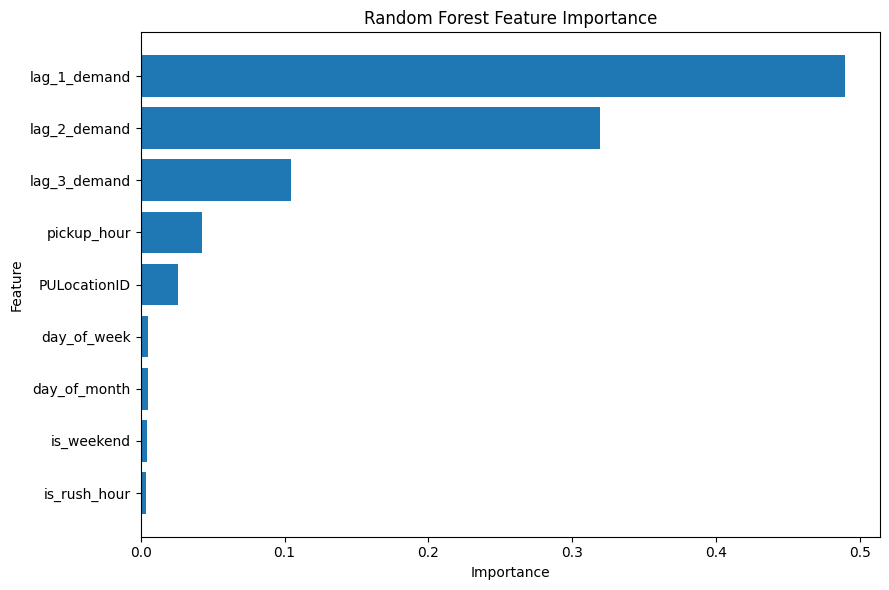


Prediction sample size used for visualization: 4,233


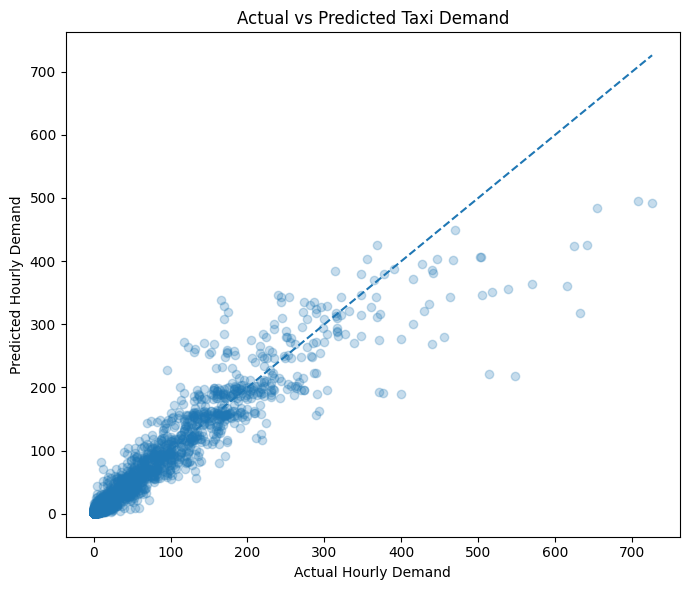

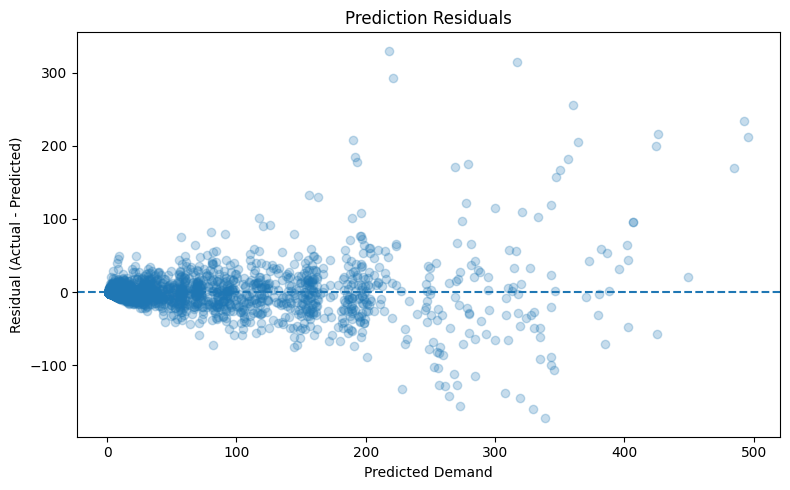


2. ERROR BY DEMAND LEVEL
+--------------+------------+-----+-----------------+
|demand_level  |observations|MAE  |avg_actual_demand|
+--------------+------------+-----+-----------------+
|High (100+)   |2735        |36.34|198.94           |
|Medium (25-99)|2956        |14.48|56.15            |
|Low (<25)     |15681       |2.29 |4.2              |
+--------------+------------+-----+-----------------+



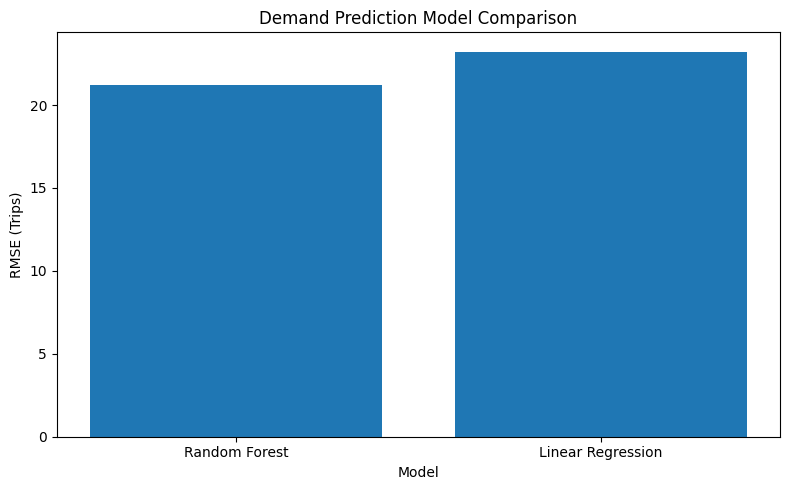


MODEL SUMMARY
Best model: Random Forest
Test RMSE: 21.23 trips
Test MAE: 8.33 trips
Test R²: 0.9194
Most influential feature: lag_1_demand (48.94% importance)
Random Forest RMSE improvement over Linear Regression: 8.61%
Random Forest MAE improvement over Linear Regression: 20.69%

Phase 8 complete.


In [14]:
# ============================================================
# PHASE 8 — MODEL INTERPRETATION & PREDICTION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

print("=" * 75)
print("MODEL INTERPRETATION & PREDICTION ANALYSIS")
print("=" * 75)


# ------------------------------------------------------------
# 1. RANDOM FOREST FEATURE IMPORTANCE
# ------------------------------------------------------------

importance_values = rf_model.featureImportances.toArray()

feature_importance = pd.DataFrame({
    "Feature": feature_columns,
    "Importance": importance_values
}).sort_values(
    "Importance",
    ascending=False
)

feature_importance["Importance_Pct"] = (
    feature_importance["Importance"] * 100
)

print("\n1. RANDOM FOREST FEATURE IMPORTANCE")

print(
    feature_importance
    .round(4)
    .to_string(index=False)
)


# ------------------------------------------------------------
# 2. FEATURE IMPORTANCE CHART
# ------------------------------------------------------------

plot_importance = feature_importance.sort_values(
    "Importance"
)

plt.figure(figsize=(9, 6))

plt.barh(
    plot_importance["Feature"],
    plot_importance["Importance"]
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. SAMPLE TEST PREDICTIONS FOR VISUALIZATION
# ------------------------------------------------------------

prediction_sample = (
    best_predictions
    .select(
        "trip_demand",
        "prediction"
    )
    .sample(
        withReplacement=False,
        fraction=0.20,
        seed=42
    )
    .limit(5000)
    .toPandas()
)

print(
    f"\nPrediction sample size used for visualization: "
    f"{len(prediction_sample):,}"
)


# ------------------------------------------------------------
# 4. ACTUAL VS PREDICTED DEMAND
# ------------------------------------------------------------

plt.figure(figsize=(7, 6))

plt.scatter(
    prediction_sample["trip_demand"],
    prediction_sample["prediction"],
    alpha=0.25
)

max_value = max(
    prediction_sample["trip_demand"].max(),
    prediction_sample["prediction"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Taxi Demand")
plt.xlabel("Actual Hourly Demand")
plt.ylabel("Predicted Hourly Demand")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. RESIDUAL ANALYSIS
# ------------------------------------------------------------

prediction_sample["residual"] = (
    prediction_sample["trip_demand"]
    - prediction_sample["prediction"]
)

plt.figure(figsize=(8, 5))

plt.scatter(
    prediction_sample["prediction"],
    prediction_sample["residual"],
    alpha=0.25
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.title("Prediction Residuals")
plt.xlabel("Predicted Demand")
plt.ylabel("Residual (Actual - Predicted)")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. ERROR BY DEMAND LEVEL
# ------------------------------------------------------------

error_analysis = (
    best_predictions

    .withColumn(
        "absolute_error",
        F.abs(
            F.col("trip_demand")
            - F.col("prediction")
        )
    )

    .withColumn(
        "demand_level",

        F.when(
            F.col("trip_demand") < 25,
            "Low (<25)"
        )

        .when(
            F.col("trip_demand") < 100,
            "Medium (25-99)"
        )

        .otherwise(
            "High (100+)"
        )
    )

    .groupBy("demand_level")

    .agg(
        F.count("*").alias("observations"),

        F.round(
            F.avg("absolute_error"),
            2
        ).alias("MAE"),

        F.round(
            F.avg("trip_demand"),
            2
        ).alias("avg_actual_demand")
    )
)

print("\n2. ERROR BY DEMAND LEVEL")

error_analysis.orderBy(
    F.desc("avg_actual_demand")
).show(
    truncate=False
)


# ------------------------------------------------------------
# 7. MODEL COMPARISON CHART
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.bar(
    model_results["Model"],
    model_results["RMSE"]
)

plt.title("Demand Prediction Model Comparison")
plt.ylabel("RMSE (Trips)")
plt.xlabel("Model")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. MODEL PERFORMANCE IMPROVEMENT
# ------------------------------------------------------------

rmse_improvement = (
    (lr_rmse - rf_rmse)
    / lr_rmse
    * 100
)

mae_improvement = (
    (lr_mae - rf_mae)
    / lr_mae
    * 100
)


# ------------------------------------------------------------
# 9. MODEL SUMMARY
# ------------------------------------------------------------

top_feature = feature_importance.iloc[0]

print("\n" + "=" * 75)
print("MODEL SUMMARY")
print("=" * 75)

print(
    f"Best model: {best_model_name}"
)

print(
    f"Test RMSE: {best_rmse:.2f} trips"
)

print(
    f"Test MAE: {best_mae:.2f} trips"
)

print(
    f"Test R²: {best_r2:.4f}"
)

print(
    f"Most influential feature: "
    f"{top_feature['Feature']} "
    f"({top_feature['Importance_Pct']:.2f}% importance)"
)

print(
    f"Random Forest RMSE improvement over "
    f"Linear Regression: {rmse_improvement:.2f}%"
)

print(
    f"Random Forest MAE improvement over "
    f"Linear Regression: {mae_improvement:.2f}%"
)

print("\nPhase 8 complete.")

## Phase 9 — Geographic Demand Analysis

Join the TLC taxi-zone lookup table to the pickup results so location IDs can be interpreted by zone and borough. Compare the busiest pickup areas and the locations generating the most pickup revenue.

NYC TAXI ZONE MAPPING & GEOGRAPHIC ANALYSIS

Taxi zones loaded: 265

1. TOP 15 PICKUP ZONES
+------------+---------+----------------------------+------------+-----------+-------------+--------------------+-----------------+
|PULocationID|Borough  |Zone                        |service_zone|total_trips|total_revenue|avg_revenue_per_trip|avg_trip_distance|
+------------+---------+----------------------------+------------+-----------+-------------+--------------------+-----------------+
|161         |Manhattan|Midtown Center              |Yellow Zone |160976     |3855188.3    |23.95               |2.21             |
|237         |Manhattan|Upper East Side South       |Yellow Zone |157643     |3134062.46   |19.88               |1.7              |
|236         |Manhattan|Upper East Side North       |Yellow Zone |149427     |3032944.49   |20.3                |2.51             |
|132         |Queens   |JFK Airport                 |Airports    |133382     |1.083440722E7|81.23               |15.

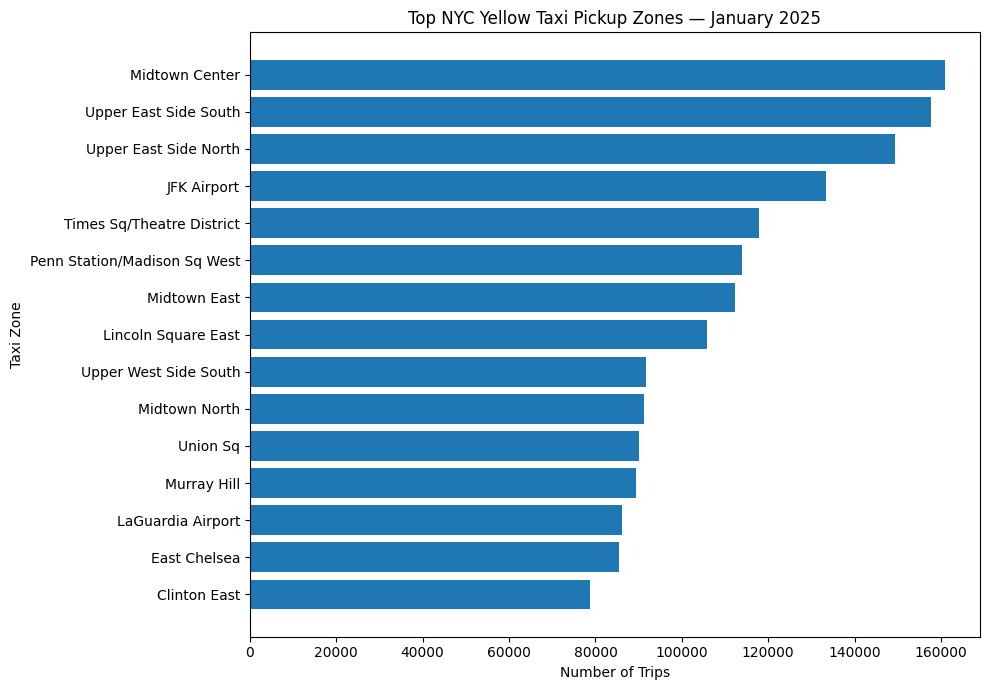

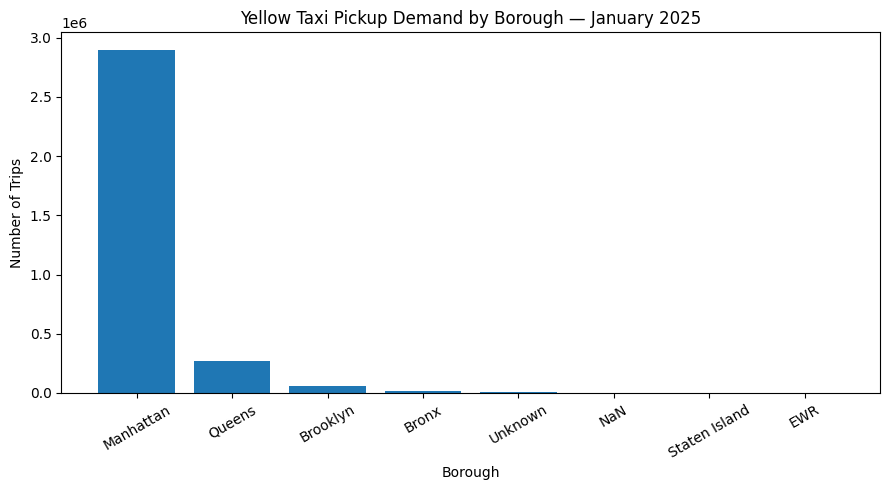


3. TOP 10 PICKUP ZONES BY REVENUE
+----------------------------+---------+-----------+-------------+--------------------+
|Zone                        |Borough  |total_trips|total_revenue|avg_revenue_per_trip|
+----------------------------+---------+-----------+-------------+--------------------+
|JFK Airport                 |Queens   |133382     |1.083440722E7|81.23               |
|LaGuardia Airport           |Queens   |86149      |6622095.4    |76.87               |
|Midtown Center              |Manhattan|160976     |3855188.3    |23.95               |
|Times Sq/Theatre District   |Manhattan|117973     |3163442.32   |26.81               |
|Upper East Side South       |Manhattan|157643     |3134062.46   |19.88               |
|Upper East Side North       |Manhattan|149427     |3032944.49   |20.3                |
|Penn Station/Madison Sq West|Manhattan|113924     |2731961.8    |23.98               |
|Midtown East                |Manhattan|112368     |2652852.06   |23.61              

In [15]:
# ============================================================
# PHASE 9 — TAXI ZONE MAPPING & GEOGRAPHIC ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

print("=" * 75)
print("NYC TAXI ZONE MAPPING & GEOGRAPHIC ANALYSIS")
print("=" * 75)


# ------------------------------------------------------------
# 1. LOAD NYC TLC TAXI ZONE LOOKUP
# ------------------------------------------------------------

zone_url = (
    "https://d37ci6vzurychx.cloudfront.net/"
    "misc/taxi_zone_lookup.csv"
)

zones_pd = pd.read_csv(zone_url)

print(f"\nTaxi zones loaded: {len(zones_pd):,}")

zones_spark = spark.createDataFrame(zones_pd)


# ------------------------------------------------------------
# 2. AGGREGATE PICKUP PERFORMANCE
# ------------------------------------------------------------

zone_performance = (
    clean_df
    .groupBy("PULocationID")
    .agg(
        F.count("*").alias("total_trips"),

        F.round(
            F.sum("trip_revenue"),
            2
        ).alias("total_revenue"),

        F.round(
            F.avg("trip_revenue"),
            2
        ).alias("avg_revenue_per_trip"),

        F.round(
            F.avg("trip_distance"),
            2
        ).alias("avg_trip_distance")
    )
)


# ------------------------------------------------------------
# 3. JOIN LOCATION IDs TO TAXI ZONE NAMES
# ------------------------------------------------------------

zone_performance = (
    zone_performance
    .join(
        zones_spark,
        zone_performance["PULocationID"]
        == zones_spark["LocationID"],
        "left"
    )
    .select(
        "PULocationID",
        "Borough",
        "Zone",
        "service_zone",
        "total_trips",
        "total_revenue",
        "avg_revenue_per_trip",
        "avg_trip_distance"
    )
)


# ------------------------------------------------------------
# 4. TOP 15 PICKUP ZONES
# ------------------------------------------------------------

top_named_zones = (
    zone_performance
    .orderBy(
        F.desc("total_trips")
    )
    .limit(15)
)

print("\n1. TOP 15 PICKUP ZONES")

top_named_zones.show(
    15,
    truncate=False
)


# ------------------------------------------------------------
# 5. BOROUGH-LEVEL ANALYSIS
# ------------------------------------------------------------

borough_analysis = (
    zone_performance

    .filter(
        F.col("Borough").isNotNull()
    )

    .groupBy("Borough")

    .agg(
        F.sum("total_trips")
        .alias("total_trips"),

        F.round(
            F.sum("total_revenue"),
            2
        ).alias("total_revenue")
    )

    .orderBy(
        F.desc("total_trips")
    )
)

print("\n2. DEMAND BY BOROUGH")

borough_analysis.show(
    truncate=False
)


# ------------------------------------------------------------
# 6. TOP PICKUP ZONES VISUALIZATION
# ------------------------------------------------------------

top_named_pd = (
    top_named_zones
    .toPandas()
    .sort_values("total_trips")
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_named_pd["Zone"],
    top_named_pd["total_trips"]
)

plt.title(
    "Top NYC Yellow Taxi Pickup Zones — January 2025"
)

plt.xlabel("Number of Trips")
plt.ylabel("Taxi Zone")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. BOROUGH DEMAND VISUALIZATION
# ------------------------------------------------------------

borough_pd = borough_analysis.toPandas()

plt.figure(figsize=(9, 5))

plt.bar(
    borough_pd["Borough"],
    borough_pd["total_trips"]
)

plt.title(
    "Yellow Taxi Pickup Demand by Borough — January 2025"
)

plt.xlabel("Borough")
plt.ylabel("Number of Trips")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 8. HIGHEST REVENUE PICKUP ZONES
# ------------------------------------------------------------

top_revenue_zones = (
    zone_performance
    .orderBy(
        F.desc("total_revenue")
    )
    .limit(10)
)

print("\n3. TOP 10 PICKUP ZONES BY REVENUE")

top_revenue_zones.select(
    "Zone",
    "Borough",
    "total_trips",
    "total_revenue",
    "avg_revenue_per_trip"
).show(
    10,
    truncate=False
)


# ------------------------------------------------------------
# 9. KEY GEOGRAPHIC FINDINGS
# ------------------------------------------------------------

highest_zone = top_named_zones.first()

highest_revenue_zone = top_revenue_zones.first()

highest_borough = borough_analysis.first()


print("\n" + "=" * 75)
print("GEOGRAPHIC SUMMARY")
print("=" * 75)

print(
    f"Highest-demand pickup zone: "
    f"{highest_zone['Zone']}, "
    f"{highest_zone['Borough']}"
)

print(
    f"Trips from highest-demand zone: "
    f"{highest_zone['total_trips']:,}"
)

print(
    f"Revenue from highest-demand zone: "
    f"${highest_zone['total_revenue']:,.2f}"
)

print(
    f"Highest-revenue pickup zone: "
    f"{highest_revenue_zone['Zone']}, "
    f"{highest_revenue_zone['Borough']}"
)

print(
    f"Highest-demand borough: "
    f"{highest_borough['Borough']} "
    f"({highest_borough['total_trips']:,} trips)"
)

print("\nPhase 9 complete.")

## Phase 10 — Final Results & Business Takeaways

Bring the main findings together, summarize practical uses of the analysis, and export the small result tables used in the project.

In [16]:
# ============================================================
# PHASE 10 — FINAL RESULTS & EXPORT
# ============================================================

import os
import pandas as pd
from pyspark.sql import functions as F

print("=" * 78)
print("NYC TAXI DEMAND ANALYTICS — PROJECT SUMMARY")
print("=" * 78)


# ------------------------------------------------------------
# 1. CREATE OUTPUT DIRECTORY
# ------------------------------------------------------------

output_dir = "/content/project_outputs"
os.makedirs(output_dir, exist_ok=True)


# ------------------------------------------------------------
# 2. SAVE MODEL PERFORMANCE
# ------------------------------------------------------------

model_results_export = model_results.copy()

model_results_export.to_csv(
    f"{output_dir}/model_performance.csv",
    index=False
)


# ------------------------------------------------------------
# 3. SAVE FEATURE IMPORTANCE
# ------------------------------------------------------------

feature_importance.to_csv(
    f"{output_dir}/feature_importance.csv",
    index=False
)


# ------------------------------------------------------------
# 4. SAVE HOURLY DEMAND
# ------------------------------------------------------------

hourly_pd.to_csv(
    f"{output_dir}/hourly_demand.csv",
    index=False
)


# ------------------------------------------------------------
# 5. SAVE DAILY DEMAND
# ------------------------------------------------------------

daily_volume_pd.to_csv(
    f"{output_dir}/daily_demand.csv",
    index=False
)


# ------------------------------------------------------------
# 6. SAVE TOP TAXI ZONES
# ------------------------------------------------------------

top_named_export = (
    top_named_zones
    .toPandas()
)

top_named_export.to_csv(
    f"{output_dir}/top_pickup_zones.csv",
    index=False
)


# ------------------------------------------------------------
# 7. SAVE BOROUGH ANALYSIS
# ------------------------------------------------------------

borough_pd.to_csv(
    f"{output_dir}/borough_demand.csv",
    index=False
)


# ------------------------------------------------------------
# 8. FINAL KPI VALUES
# ------------------------------------------------------------

total_trips = clean_rows

total_revenue = (
    clean_df
    .agg(
        F.sum("trip_revenue")
        .alias("revenue")
    )
    .first()["revenue"]
)

avg_trip_revenue = total_revenue / total_trips


# ------------------------------------------------------------
# 9. PEAK DEMAND INFORMATION
# ------------------------------------------------------------

peak_hour_final = (
    hourly_demand
    .orderBy(
        F.desc("total_trips")
    )
    .first()
)

peak_day_final = (
    daily_demand
    .orderBy(
        F.desc("total_trips")
    )
    .first()
)


# ------------------------------------------------------------
# 10. GEOGRAPHIC INFORMATION
# ------------------------------------------------------------

highest_zone_final = (
    top_named_zones
    .orderBy(
        F.desc("total_trips")
    )
    .first()
)

highest_revenue_zone_final = (
    top_revenue_zones
    .orderBy(
        F.desc("total_revenue")
    )
    .first()
)

highest_borough_final = (
    borough_analysis
    .orderBy(
        F.desc("total_trips")
    )
    .first()
)


# ------------------------------------------------------------
# 11. EXECUTIVE SUMMARY
# ------------------------------------------------------------

print("\n1. SCALE OF ANALYSIS")
print("-" * 78)

print(
    f"Clean taxi trips analyzed: "
    f"{total_trips:,}"
)

print(
    f"Total trip revenue analyzed: "
    f"${total_revenue:,.2f}"
)

print(
    f"Average revenue per trip: "
    f"${avg_trip_revenue:,.2f}"
)


print("\n2. DEMAND PATTERNS")
print("-" * 78)

print(
    f"Peak demand hour: "
    f"{peak_hour_final['pickup_hour']}:00 "
    f"with {peak_hour_final['total_trips']:,} trips"
)

print(
    f"Highest-demand weekday: "
    f"{peak_day_final['day_name']} "
    f"with {peak_day_final['total_trips']:,} trips"
)


print("\n3. GEOGRAPHIC CONCENTRATION")
print("-" * 78)

print(
    f"Highest-demand pickup zone: "
    f"{highest_zone_final['Zone']}, "
    f"{highest_zone_final['Borough']} "
    f"({highest_zone_final['total_trips']:,} trips)"
)

print(
    f"Highest-revenue pickup zone: "
    f"{highest_revenue_zone_final['Zone']}, "
    f"{highest_revenue_zone_final['Borough']} "
    f"(${highest_revenue_zone_final['total_revenue']:,.2f})"
)

print(
    f"Highest-demand borough: "
    f"{highest_borough_final['Borough']} "
    f"({highest_borough_final['total_trips']:,} trips)"
)


print("\n4. MACHINE LEARNING PERFORMANCE")
print("-" * 78)

print(
    f"Best model: {best_model_name}"
)

print(
    f"Test RMSE: {best_rmse:.2f} trips"
)

print(
    f"Test MAE: {best_mae:.2f} trips"
)

print(
    f"Test R²: {best_r2:.4f}"
)

print(
    f"Most influential predictor: "
    f"{top_feature['Feature']} "
    f"({top_feature['Importance_Pct']:.2f}% importance)"
)

print(
    f"RMSE improvement over Linear Regression: "
    f"{rmse_improvement:.2f}%"
)

print(
    f"MAE improvement over Linear Regression: "
    f"{mae_improvement:.2f}%"
)


# ------------------------------------------------------------
# 12. BUSINESS RECOMMENDATIONS
# ------------------------------------------------------------

print("\n5. BUSINESS RECOMMENDATIONS")
print("-" * 78)

recommendations = [
    "Increase vehicle availability during the late-afternoon and evening demand peak, particularly around 17:00–19:00.",

    "Prioritize high-volume Manhattan pickup zones when planning vehicle positioning and driver coverage.",

    "Treat airport demand separately from ordinary high-volume zones because airport pickups can generate substantially higher revenue per trip.",

    "Use recent observed zone-level demand as a major signal in short-term demand forecasting because lagged demand variables were the strongest model predictors.",

    "Use demand forecasts to support dynamic fleet allocation, driver positioning, and peak-period capacity planning.",

    "Monitor prediction errors during extreme high-demand periods because model error increases when hourly demand becomes unusually high."
]

for i, recommendation in enumerate(
    recommendations,
    start=1
):
    print(
        f"{i}. {recommendation}"
    )


# ------------------------------------------------------------
# 13. CREATE FINAL SUMMARY FILE
# ------------------------------------------------------------

summary_text = f"""
NYC TAXI DEMAND PREDICTION & BIG DATA ANALYTICS PLATFORM
========================================================

DATASET
Clean trips analyzed: {total_trips:,}
Total revenue analyzed: ${total_revenue:,.2f}
Average revenue per trip: ${avg_trip_revenue:,.2f}

DEMAND
Peak demand hour: {peak_hour_final['pickup_hour']}:00
Peak-hour trips: {peak_hour_final['total_trips']:,}
Highest-demand weekday: {peak_day_final['day_name']}

GEOGRAPHY
Highest-demand pickup zone: {highest_zone_final['Zone']}, {highest_zone_final['Borough']}
Highest-revenue pickup zone: {highest_revenue_zone_final['Zone']}, {highest_revenue_zone_final['Borough']}
Highest-demand borough: {highest_borough_final['Borough']}

MACHINE LEARNING
Best model: {best_model_name}
Test RMSE: {best_rmse:.2f}
Test MAE: {best_mae:.2f}
Test R²: {best_r2:.4f}
Most influential predictor: {top_feature['Feature']}
Random Forest RMSE improvement over Linear Regression: {rmse_improvement:.2f}%
Random Forest MAE improvement over Linear Regression: {mae_improvement:.2f}%

BUSINESS APPLICATION
The analysis demonstrates how large-scale trip records can be transformed
into operational demand intelligence using PySpark, Spark SQL, feature
engineering, and machine learning. The resulting forecasting framework can
support vehicle allocation, driver positioning, geographic planning, and
peak-demand capacity decisions.
"""

with open(
    f"{output_dir}/executive_summary.txt",
    "w"
) as file:
    file.write(summary_text)


# ------------------------------------------------------------
# 14. VERIFY EXPORTED FILES
# ------------------------------------------------------------

print("\n6. EXPORTED PROJECT FILES")
print("-" * 78)

for filename in sorted(
    os.listdir(output_dir)
):
    print(
        f"✓ {filename}"
    )


print("\n" + "=" * 78)
print("PROJECT ANALYSIS COMPLETE")
print("=" * 78)

print(
    "\nAll analytical phases have been completed successfully."
)

NYC TAXI DEMAND ANALYTICS — FINAL EXECUTIVE SUMMARY

1. SCALE OF ANALYSIS
------------------------------------------------------------------------------
Clean taxi trips analyzed: 3,241,808
Total trip revenue analyzed: $87,679,823.74
Average revenue per trip: $27.05

2. DEMAND PATTERNS
------------------------------------------------------------------------------
Peak demand hour: 18:00 with 235,843 trips
Highest-demand weekday: Thursday with 569,851 trips

3. GEOGRAPHIC CONCENTRATION
------------------------------------------------------------------------------
Highest-demand pickup zone: Midtown Center, Manhattan (160,976 trips)
Highest-revenue pickup zone: JFK Airport, Queens ($10,834,407.22)
Highest-demand borough: Manhattan (2,899,553 trips)

4. MACHINE LEARNING PERFORMANCE
------------------------------------------------------------------------------
Best model: Random Forest
Test RMSE: 21.23 trips
Test MAE: 8.33 trips
Test R²: 0.9194
Most influential predictor: lag_1_demand (48.

# Final Business Takeaways

After cleaning, the analysis included 3.24 million NYC Yellow Taxi trips from January 2025. Demand was concentrated in specific times and locations: 18:00 was the busiest pickup hour, Thursday had the highest trip volume by weekday, and Manhattan accounted for most pickups in the dataset.

Midtown Center had the highest pickup volume with 160,976 trips. JFK Airport generated the highest pickup revenue, showing that the busiest location by trip count is not necessarily the highest-revenue location.

Random Forest performed better than the Linear Regression baseline on the held-out final week of January. It achieved an R² of 0.9194, RMSE of 21.23 trips, and MAE of 8.33 trips. The previous observed demand variables were the strongest predictors, with `lag_1_demand` contributing 48.94% of the Random Forest feature importance.

Prediction errors were much larger for high-demand observations than for low-demand observations. This suggests that unusual demand spikes are harder for the current model to capture and are an important area for improvement.

## Business Use

The results could support short-term vehicle allocation and driver positioning by highlighting peak periods and high-demand pickup zones. Airport demand should also be considered separately because high pickup revenue does not always align with the locations that have the largest number of trips.

## Limitations and Next Steps

This project uses January 2025 Yellow Taxi data, and model performance is measured on the final week of that month. The results should therefore be treated as performance for this dataset and test period rather than evidence that the same accuracy will hold in other months or seasons.

The lag features represent previous observed zone-level demand records rather than a complete continuous hourly series. A future version could build a full zone-hour panel and add more months of data, weather, holidays, major events, and traffic conditions.